--- Verificación del Modelo de Dothan ---
Media Teórica:    0.050000 | Media Simulada:    0.050018
Varianza Teórica: 2.512542e-05 | Varianza Simulada: 2.514268e-05


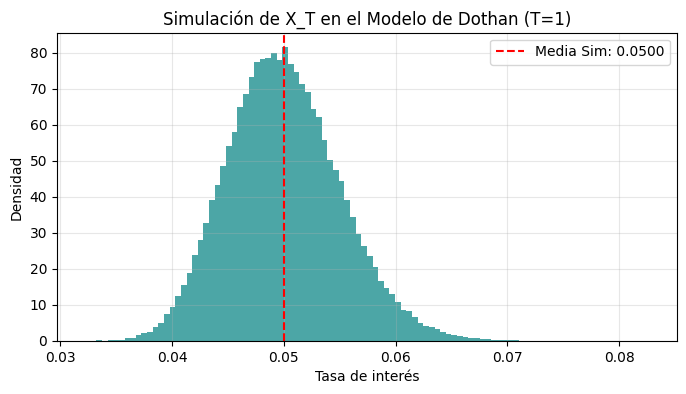

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Parámetros
X0 = 0.05       # Tasa de interés inicial (5%)
sigma = 0.1     # Volatilidad
T = 1.0         # Tiempo final (1 año)
N_sim = 100000  # Número de simulaciones

# Simulamos W_T ~ N(0, T)
W_T = np.random.normal(0, np.sqrt(T), N_sim)

# Aplicamos la solución exacta X_T = X0 * exp(sigma*W_T - 0.5*sigma^2*T)
X_T = X0 * np.exp(sigma * W_T - 0.5 * sigma**2 * T)

# Resultados teóricos
media_teorica = X0
var_teorica = X0**2 * (np.exp(sigma**2 * T) - 1)

# Resultados simulados
media_sim = np.mean(X_T)
var_sim = np.var(X_T)

print("--- Verificación del Modelo de Dothan ---")
print(f"Media Teórica:    {media_teorica:.6f} | Media Simulada:    {media_sim:.6f}")
print(f"Varianza Teórica: {var_teorica:.6e} | Varianza Simulada: {var_sim:.6e}")

# Histograma
plt.figure(figsize=(8, 4))
plt.hist(X_T, bins=100, density=True, color='teal', alpha=0.7)
plt.axvline(media_sim, color='red', linestyle='--', label=f'Media Sim: {media_sim:.4f}')
plt.title('Simulación de X_T en el Modelo de Dothan (T=1)')
plt.xlabel('Tasa de interés')
plt.ylabel('Densidad')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

--- Resultados (Semilla 43) ---
Probabilidad estimada P(X_3 > 5.01): 0.4764
Valor final de la ruta graficada: 4.3678
¿La ruta graficada superó el umbral?: No


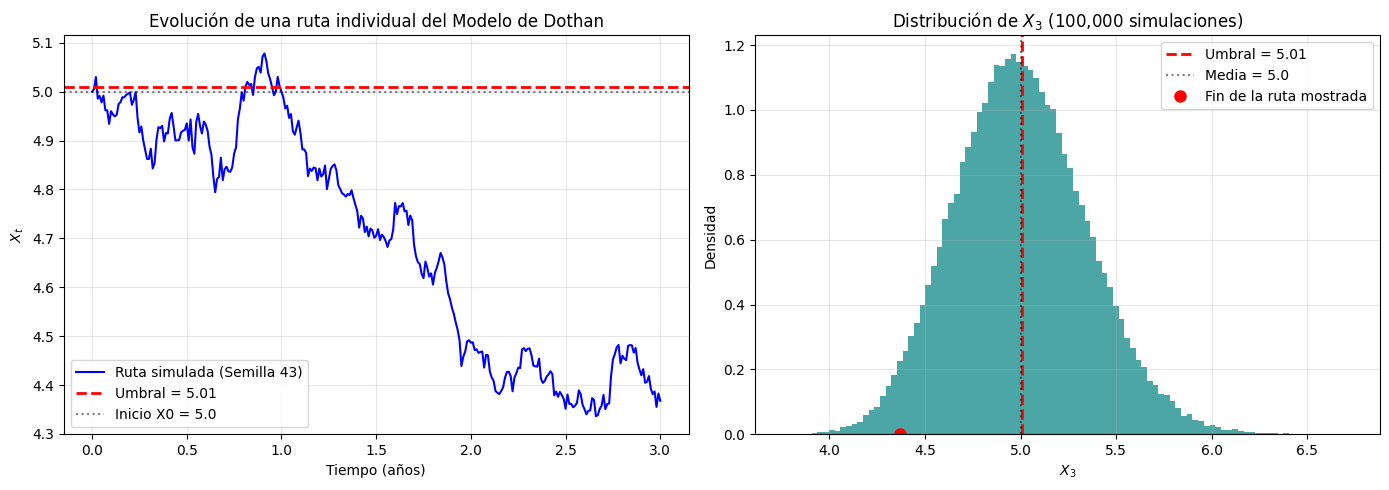

In [4]:
# 1. Parámetros del problema
X0 = 5.0
sigma = 0.04
T = 3.0
umbral = 5.01

# Parámetros de simulación
N_sim = 100000    
dt = 0.01         
N_pasos = int(T / dt)  

# Fijamos la semilla para que la ruta sea siempre la misma
np.random.seed(43)

# 2. Simulación con Euler-Maruyama (Vectorizada)
X = np.full(N_sim, X0)

# Arreglo para guardar el historial de la primera ruta (índice 0)
tiempo = np.linspace(0, T, N_pasos + 1)
ruta_historial = np.zeros(N_pasos + 1)
ruta_historial[0] = X0

for i in range(N_pasos):
    # Generamos los incrementos brownianos para TODAS las simulaciones
    dW = np.random.normal(0, np.sqrt(dt), N_sim)
    
    # Aplicamos Euler-Maruyama
    X = X + sigma * X * dW
    
    # Guardamos el valor del paso actual para la primera ruta (X[0])
    ruta_historial[i + 1] = X[0]

# 3. Cálculo de la probabilidad
prob_sim = np.mean(X > umbral)

# Verificamos si nuestra ruta de ejemplo superó el umbral al final
supero_umbral = ruta_historial[-1] > umbral

print("--- Resultados (Semilla 43) ---")
print(f"Probabilidad estimada P(X_3 > {umbral}): {prob_sim:.4f}")
print(f"Valor final de la ruta graficada: {ruta_historial[-1]:.4f}")
print(f"¿La ruta graficada superó el umbral?: {'Sí' if supero_umbral else 'No'}")

# 4. Visualización (Trayectoria y Histograma)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# --- Gráfico 1: Trayectoria Individual ---
ax1.plot(tiempo, ruta_historial, color='blue', lw=1.5, label='Ruta simulada (Semilla 43)')
ax1.axhline(umbral, color='red', linestyle='--', lw=2, label=f'Umbral = {umbral}')
ax1.axhline(X0, color='black', linestyle=':', alpha=0.5, label=f'Inicio X0 = {X0}')
ax1.set_title('Evolución de una ruta individual del Modelo de Dothan')
ax1.set_xlabel('Tiempo (años)')
ax1.set_ylabel('$X_t$')
ax1.legend()
ax1.grid(True, alpha=0.3)

# --- Gráfico 2: Histograma de Valores Finales ---
ax2.hist(X, bins=100, density=True, color='teal', alpha=0.7)
ax2.axvline(umbral, color='red', linestyle='--', lw=2, label=f'Umbral = {umbral}')
ax2.axvline(X0, color='black', linestyle=':', alpha=0.5, label=f'Media = {X0}')
# Marcamos con un punto rojo dónde terminó la ruta individual
ax2.plot(ruta_historial[-1], 0, 'ro', markersize=8, label='Fin de la ruta mostrada')
ax2.set_title('Distribución de $X_3$ (100,000 simulaciones)')
ax2.set_xlabel('$X_3$')
ax2.set_ylabel('Densidad')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

--- Log-Return Exacto ---
Media Teórica:    -0.000800 | Media Simulada:    -0.000613
Varianza Teórica: 0.001600 | Varianza Simulada: 0.001595

--- Log-Return Euler-Maruyama ---
Media Simulada:    -0.000612
Varianza Simulada: 0.001601


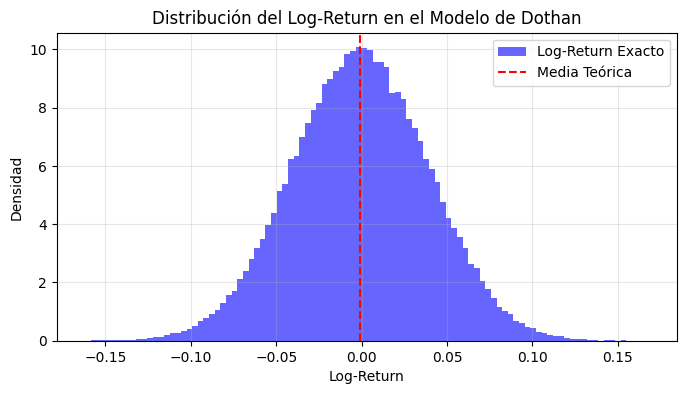

In [5]:
# Parámetros
sigma = 0.04
N_sim = 100000

# 1. Log-Return Exacto (Fórmula cerrada)
# R_t = sigma * Z - 0.5 * sigma^2
Z = np.random.normal(0, 1, N_sim)
R_exacto = sigma * Z - 0.5 * sigma**2

# 2. Log-Return por Euler-Maruyama (Discretización)
# R_t = ln(1 + sigma * Z)
R_euler = np.log(1 + sigma * Z)

print("--- Log-Return Exacto ---")
print(f"Media Teórica:    {-0.5 * sigma**2:.6f} | Media Simulada:    {np.mean(R_exacto):.6f}")
print(f"Varianza Teórica: {sigma**2:.6f} | Varianza Simulada: {np.var(R_exacto):.6f}")

print("\n--- Log-Return Euler-Maruyama ---")
print(f"Media Simulada:    {np.mean(R_euler):.6f}")
print(f"Varianza Simulada: {np.var(R_euler):.6f}")

# Gráfico
plt.figure(figsize=(8, 4))
plt.hist(R_exacto, bins=100, density=True, alpha=0.6, color='blue', label='Log-Return Exacto')
plt.axvline(-0.5 * sigma**2, color='red', linestyle='--', label='Media Teórica')
plt.title('Distribución del Log-Return en el Modelo de Dothan')
plt.xlabel('Log-Return')
plt.ylabel('Densidad')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()